# Tarea 2 – Parte 1: Corpus y extracción (OCR + ASR)

> **Pregunta guía:** ¿Pueden convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

Este notebook extrae texto de documentos peruanos con **PaddleOCR**, transcribe audios en español peruano con **faster-whisper** (VAD y diarización), seudonimiza los textos, limpia el corpus, hace un EDA y exporta `datos/documentos.csv`, `datos/transcripciones.csv` y `datos/fuentes.csv`.

## 1. Configuración inicial

### Fecha de extracción

| Corpus | Fecha |
|---|---|
| A. Documentos | 25/10/2026 |
| B. Audio | 25/10/2026 |

### Fuentes y licencias

**Corpus A – Documentos** (`datos/raw/documentos/`, 25 imágenes)

| Archivos | Fuente | Licencia |
|---|---|---|
| `Impreso-nitido-1` … `8` | Revista *Fénix* (Biblioteca Nacional del Perú), n.º 19, 1969. Núñez, E. «Un manuscrito autógrafo y desconocido de Mariano Melgar», pp. 67-77. DOI [10.51433/fenix-bnp.1969.n19.p67-77](https://doi.org/10.51433/fenix-bnp.1969.n19.p67-77) · [artículo](https://revistafenix.bnp.gob.pe/index.php/fenix/article/view/515) | CC BY-NC-ND 4.0 |
| `sombras-inclinacion-1`, `2` | Fotografía propia de *THĒMIS-Revista de Derecho* n.º 88 (jul.-dic. 2025), pp. 65-88 y 255-280 · [ficha](https://themis.com.pe/producto/revista-88-derecho-constitucional/) | CC BY 4.0 (licencia de los artículos de THĒMIS 88, p. ej. [artículo 33548](https://revistas.pucp.edu.pe/index.php/themis/es/article/view/33548)) |
| `sombras-inclinacion-3`, `4` | Fotografía propia de *Estudio de anulación de laudos 2022*, pp. 24 y 45. Centro de Arbitraje de la Cámara de Comercio de Lima · [PDF](https://www.arbitrajeccl.com.pe/wp-content/uploads/2024/04/Estudio-de-anulacion-de-laudos-2022.pdf) | Acceso libre, sin licencia declarada (derechos reservados); captura propia para uso académico |
| `sombras-inclinacion-5` … `8` | Fotografía propia de *THĒMIS-Revista de Derecho* n.º 81 (2022), *Derecho Bancario y Financiero*: pp. 169-185 ([artículo 26498](https://revistas.pucp.edu.pe/index.php/themis/es/article/view/26498)) y pp. 43-61 ([artículo 26490](https://revistas.pucp.edu.pe/index.php/themis/es/article/view/26490)) · [número](https://revistas.pucp.edu.pe/index.php/themis/es/issue/view/1850) | CC BY 4.0 |
| `Manuscrito-1`, `2`, `3.1`–`3.3`, `4.1`–`4.3`, `5` | Biblioteca Digital de la Biblioteca Nacional del Perú: [ítem d2c6e978](https://bibliotecadigital.bnp.gob.pe/items/d2c6e978-52d4-4bb0-9f95-5104a308837c) · [ítem 00383e3a](https://bibliotecadigital.bnp.gob.pe/items/00383e3a-518b-4397-9dcb-fe2710f3ab7b) · [ítem 661a505e](https://bibliotecadigital.bnp.gob.pe/items/661a505e-5dc5-411a-a174-2ef8499bd0f7) · [ítem 5bd20bc1](https://bibliotecadigital.bnp.gob.pe/items/5bd20bc1-c0b3-49c6-9beb-c2f5bc467bb6) | Dominio público (Creative Commons), según la ficha de cada ítem en BNP Digital |

Las fotografías son capturas propias de libros impresos y no contienen datos personales. Las imágenes con derechos reservados (`sombras-inclinacion-3` y `4`) no se publican en el dashboard: de ellas solo se muestran el texto OCR y los metadatos.

**Corpus B – Audio** (`datos/raw/audio/`, 20 clips descargados de Wikimedia Commons y convertidos a WAV mono de 16 kHz; detalle por clip en `datos/raw/audio/manifiesto_descarga.csv`)

| Clips | Contenido | Autores en Commons | Licencia |
|---|---|---|---|
| `clip_001` … `clip_007` | Entrevistas en la calle en Lima (El Agustino, Magdalena; Fiestas Patrias 2022) | JorgeFlores-pe, Rosario MQ, Christopher Bellido, Mayhely Aida, QM Keen | CC BY-SA 4.0 |
| `clip_008` … `clip_011` | Lectura en voz alta de artículos de Wikipedia sobre huacas de Lima (2022) | Ariana zafra, Stefanya E. Trujillo Mendoza, Jhon Manayay, Lucía Pérez2 | CC BY-SA 4.0 |
| `clip_012` … `clip_020` | Entrevistas rurales sobre plantas medicinales en Shansha, Áncash (2026) | Figuemijun | CC BY-SA 4.0 |

Los clips `clip_012` … `clip_018` se **descartan** del corpus en español porque las respuestas están principalmente en quechua de Áncash (ver sección 3.1 y la limpieza). Los títulos de Commons incluyen nombres reales de las personas entrevistadas: en las transcripciones publicadas esos nombres se seudonimizan (sección 4).

La URL, la licencia y el procedimiento de recuperación de cada archivo se detallan en `datos/fuentes.csv`. Los archivos originales no se versionan en Git (`datos/raw/` está en `.gitignore`).

### Versiones y entorno

| Componente | Versión / configuración |
|---|---|
| Python | 3.12.15 (kernel `ds-python-up`) |
| Entorno | Repositorio del curso, `uv sync --group docai --group audio` |
| OCR | PaddleOCR 3.7.0 sobre PaddlePaddle 3.3.1 (`lang=es`, CPU) |
| ASR | faster-whisper 1.2.1 con `mobiuslabsgmbh/faster-whisper-large-v3-turbo` (CTranslate2 int8, CPU) mediante `voz.py` (Sesión 13, copiado en `tarea_2/voz.py`) |
| VAD | Silero VAD integrado en faster-whisper |
| Diarización | pyannote.audio 4.0.7 (embeddings `pyannote/wespeaker-voxceleb-resnet34-LM`) + clustering aglomerativo de `voz.py` |


In [1]:
import hashlib
import json
import os
import re
import time
import warnings
from datetime import date
from pathlib import Path

# Esta línea va ANTES de importar PaddleOCR: no probar la conexión a cada servidor de modelos
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
warnings.filterwarnings("ignore")

# paddleocr va ANTES que paddle: en Windows, importar paddle primero impide que torch
# cargue sus DLL (OSError WinError 127 en torch\lib\shm.dll)
import paddleocr
from paddleocr import PaddleOCR
import paddle
import pandas as pd
from PIL import Image, ImageDraw

pd.set_option("display.max_colwidth", 120)

DATOS = Path("datos")
DOCS = DATOS / "raw" / "documentos"   # imágenes originales (no se versionan)
OCR_CRUDO = DOCS / "ocr"              # respaldo crudo: un JSON y una imagen anotada por documento
RECORTES = DOCS / "recortes"          # un recorte por cada línea de texto detectada
for carpeta in (OCR_CRUDO, RECORTES):
    carpeta.mkdir(parents=True, exist_ok=True)

print(f"Fecha de ejecución: {date.today():%d/%m/%Y}")
print(f"PaddleOCR {paddleocr.__version__} · PaddlePaddle {paddle.__version__} · dispositivo: {paddle.device.get_device()}")

Fecha de ejecución: 26/10/2026
PaddleOCR 3.7.0 · PaddlePaddle 3.3.1 · dispositivo: cpu


## 2. OCR de documentos (Sesión 10)

### 2.1 Inventario del corpus

Cada imagen recibe un `id` estable (`doc_001` … `doc_025`, ordenados por tipo y número de archivo). El tipo se deduce del nombre del archivo, y el hash SHA-256 de cada archivo servirá después para detectar duplicados en la limpieza.

In [2]:
TIPOS = {"Impreso-nitido": "impreso", "sombras-inclinacion": "foto", "Manuscrito": "manuscrito"}
ORDEN_TIPOS = list(TIPOS.values())


def tipo_de(ruta):
    return next(tipo for prefijo, tipo in TIPOS.items() if ruta.stem.startswith(prefijo))


def numero_de(ruta):
    "Número del archivo como float, para que Manuscrito-3.2 quede entre 3.1 y 3.3."
    return float(re.search(r"-(\d+(?:\.\d+)?)$", ruta.stem).group(1))


rutas = sorted(
    (p for p in DOCS.iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg"}),
    key=lambda p: (ORDEN_TIPOS.index(tipo_de(p)), numero_de(p)),
)

inventario = pd.DataFrame({
    "id": [f"doc_{i:03d}" for i in range(1, len(rutas) + 1)],
    "archivo": [p.as_posix() for p in rutas],
    "tipo": [tipo_de(p) for p in rutas],
    "resolucion": [f"{w}x{h}" for w, h in (Image.open(p).size for p in rutas)],
    "hash": [hashlib.sha256(p.read_bytes()).hexdigest() for p in rutas],
})

print(f"{len(inventario)} documentos")
print(inventario.tipo.value_counts().reindex(ORDEN_TIPOS).to_string())
inventario

25 documentos
tipo
impreso       8
foto          8
manuscrito    9


,id,archivo,tipo,resolucion,hash
0,doc_001,datos/raw/documentos/Impreso-nitido-1.png,impreso,511x778,5f770338bd1486eaf90e087089b1b181b5a6e01e7f986340cc41c9bfbd1e11aa
1,doc_002,datos/raw/documentos/Impreso-nitido-2.png,impreso,492x774,4dd823f32caf77b3ff4d90b6410977a1c9412e13383e3a892ab007ef77d480ad
2,doc_003,datos/raw/documentos/Impreso-nitido-3.png,impreso,498x714,8e955d1461d40899510afd24249d5f85fd37a8c9ab5ae9bf97eccd655ec6a26b
3,doc_004,datos/raw/documentos/Impreso-nitido-4.png,impreso,496x767,7f2dd8e9e6fbe0ee7b8da28f8ddfda697ad3cfebbe3039c77f761a414dcb94a0
4,doc_005,datos/raw/documentos/Impreso-nitido-5.png,impreso,494x775,a4671e440ee47fa74b06c9a67de77ee81e85352e60c7d6d79da34bcd29622b45
5,doc_006,datos/raw/documentos/Impreso-nitido-6.png,impreso,484x754,f341fc90b662205ad58cb48dfcee0f549539cbcff5f337b60b67b54e4ead241a
6,doc_007,datos/raw/documentos/Impreso-nitido-7.png,impreso,500x773,8bc3cff88ea74c54b69f0c9ea5a532aa95ef2efe26bb6e7fc9cc9cca010d483f
7,doc_008,datos/raw/documentos/Impreso-nitido-8.png,impreso,488x781,4de7bd3441959dc5fadf4d97cbed32bb762dd8427bc53f77ed2d466ec5f7efe6
8,doc_009,datos/raw/documentos/sombras-inclinacion-1.jpg,foto,936x1402,3eec1642bf83c4f43a008ee29fe250e7708a93cef29728861cffc9c90aa4c107
9,doc_010,datos/raw/documentos/sombras-inclinacion-2.jpg,foto,808x1268,3803145fd96e4340f19c321a2d55a6945f775cf59574ee6107d1a34fd49b06ff


### 2.2 Extracción con PaddleOCR

**Parámetros** (iguales para los tres tipos de documento, fijados antes de ver resultados):

| Parámetro | Valor | Motivo |
|---|---|---|
| Idioma | `lang="es"` | PaddleOCR 3.7 selecciona `PP-OCRv6_medium_det` + `PP-OCRv6_medium_rec`, que reconocen tildes y ñ |
| Dispositivo | `device="cpu"` | El equipo no tiene GPU NVIDIA |
| oneDNN | `enable_mkldnn=False` | Con oneDNN activo, PaddlePaddle 3.3 en Windows falla en cada inferencia (`NotImplementedError: ConvertPirAttribute2RuntimeAttribute not support`); sin él funciona, algo más lento |
| Clasificador de orientación de página | desactivado | Todas las páginas están derechas |
| Corrección de deformación (*unwarping*) | desactivada | Puede deformar páginas planas; se deja el desempeño "en bruto" de las fotos para la evaluación |
| Orientación por línea | desactivada | No hay líneas giradas 180° |
| Preprocesamiento | ninguno adicional | Las imágenes entran tal como se descargaron o fotografiaron; el detector aplica su redimensionamiento interno por defecto |

Por cada documento se guarda en `datos/raw/documentos/ocr/` un **respaldo crudo** (`doc_XXX.json` con textos, confianzas y cajas, más `doc_XXX_cajas.png` con las cajas dibujadas), y en `datos/raw/documentos/recortes/doc_XXX/` el **recorte** de cada línea detectada. Si el respaldo ya existe, se reutiliza en lugar de volver a correr el modelo (en CPU, el OCR tarda alrededor de 1 a 3 minutos por página).

El texto de cada documento se arma uniendo las líneas en el orden en que PaddleOCR las entrega (de arriba hacia abajo). En páginas a dos columnas ese orden puede intercalar líneas de ambas columnas.

In [3]:
CONFIG_OCR = dict(
    lang="es",
    device="cpu",
    enable_mkldnn=False,
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)
MODELO_OCR = "PaddleOCR 3.7 · PP-OCRv6_medium (lang=es, CPU, sin preprocesamiento)"

_ocr = None


def modelo_ocr():
    "Construye PaddleOCR una sola vez, y solo si algún documento no tiene respaldo."
    global _ocr
    if _ocr is None:
        t0 = time.perf_counter()
        _ocr = PaddleOCR(**CONFIG_OCR)
        print(f"Modelo cargado en {time.perf_counter() - t0:.0f} s")
    return _ocr


def guardar_cajas_y_recortes(id_doc, archivo, cajas):
    "Guarda un recorte por línea detectada y una copia de la página con las cajas dibujadas."
    imagen = Image.open(archivo).convert("RGB")
    carpeta = RECORTES / id_doc
    carpeta.mkdir(exist_ok=True)
    for k, caja in enumerate(cajas):
        imagen.crop(caja).save(carpeta / f"linea_{k:03d}.png")
    anotada = imagen.copy()
    dibujo = ImageDraw.Draw(anotada)
    for caja in cajas:
        dibujo.rectangle(caja, outline=(220, 30, 30), width=2)
    anotada.save(OCR_CRUDO / f"{id_doc}_cajas.png")


def leer_documento(id_doc, archivo):
    "OCR de una imagen. Si ya existe su respaldo crudo, lo reutiliza en vez de volver a correr el modelo."
    respaldo = OCR_CRUDO / f"{id_doc}.json"
    if respaldo.exists():
        return json.loads(respaldo.read_text(encoding="utf-8")), True
    t0 = time.perf_counter()
    r = modelo_ocr().predict(archivo)[0]
    crudo = {
        "id": id_doc,
        "archivo": archivo,
        "modelo_ocr": MODELO_OCR,
        "parametros": CONFIG_OCR,
        "segundos": round(time.perf_counter() - t0, 1),
        "textos": list(r["rec_texts"]),
        "confianzas": [round(float(s), 4) for s in r["rec_scores"]],
        "cajas": [[int(v) for v in caja] for caja in r["rec_boxes"]],   # x0, y0, x1, y1 de cada línea
    }
    respaldo.write_text(json.dumps(crudo, ensure_ascii=False, indent=1), encoding="utf-8")
    guardar_cajas_y_recortes(id_doc, archivo, crudo["cajas"])
    return crudo, False


filas = []
for doc in inventario.itertuples():
    crudo, reutilizado = leer_documento(doc.id, doc.archivo)
    confianzas = crudo["confianzas"]
    filas.append({
        "id": doc.id,
        "texto_ocr": "\n".join(crudo["textos"]),
        "modelo_ocr": crudo["modelo_ocr"],
        "n_lineas": len(crudo["textos"]),
        "confianza_media": round(sum(confianzas) / len(confianzas), 3) if confianzas else 0.0,
        "segundos_ocr": crudo["segundos"],
    })
    origen = "respaldo" if reutilizado else "OCR"
    print(f"{doc.id} {doc.tipo:<10} {filas[-1]['n_lineas']:>3} líneas · "
          f"confianza {filas[-1]['confianza_media']:.2f} · {crudo['segundos']:>5.0f} s ({origen})")

ocr_docs = inventario.merge(pd.DataFrame(filas), on="id")

doc_001 impreso     33 líneas · confianza 0.99 ·    92 s (respaldo)
doc_002 impreso     60 líneas · confianza 1.00 ·   137 s (respaldo)
doc_003 impreso     40 líneas · confianza 0.99 ·   165 s (respaldo)
doc_004 impreso     43 líneas · confianza 0.99 ·   162 s (respaldo)
doc_005 impreso     46 líneas · confianza 0.99 ·    94 s (respaldo)
doc_006 impreso     39 líneas · confianza 1.00 ·    96 s (respaldo)
doc_007 impreso     44 líneas · confianza 0.99 ·   168 s (respaldo)
doc_008 impreso     47 líneas · confianza 0.99 ·   120 s (respaldo)
doc_009 foto       119 líneas · confianza 0.98 ·   200 s (respaldo)
doc_010 foto       107 líneas · confianza 0.97 ·   145 s (respaldo)
doc_011 foto        28 líneas · confianza 0.98 ·    79 s (respaldo)
doc_012 foto        24 líneas · confianza 0.96 ·    80 s (respaldo)
doc_013 foto        95 líneas · confianza 0.97 ·   150 s (respaldo)
doc_014 foto        94 líneas · confianza 0.96 ·   232 s (respaldo)
doc_015 foto        78 líneas · confianza 0.95 ·

In [4]:
resumen_ocr = (
    ocr_docs.groupby("tipo", sort=False)
    .agg(documentos=("id", "size"),
         lineas_promedio=("n_lineas", "mean"),
         confianza_media=("confianza_media", "mean"),
         minutos_ocr=("segundos_ocr", lambda s: s.sum() / 60))
    .round(2)
)
display(resumen_ocr)

# Un ejemplo por tipo: las primeras líneas reconocidas
for tipo, grupo in ocr_docs.groupby("tipo", sort=False):
    doc = grupo.iloc[0]
    print(f"━━ {doc.id} ({tipo}) · {doc.archivo}")
    print(doc.texto_ocr[:400], "\n")

,documentos,lineas_promedio,confianza_media,minutos_ocr
tipo,,,,
impreso,8,44.00,0.99,17.23
foto,8,77.38,0.97,21.16
manuscrito,9,21.11,0.81,8.46


━━ doc_001 (impreso) · datos/raw/documentos/Impreso-nitido-1.png
UN MANUSCRITO AUTOGRAFO Y DESCONOCIDO
DE MARIANO MELGAR
Estuardo Núñez
La Biblioteca de Lilly de la Universidad de Indiana ha adquirido última-
mente un fondo muy nutrido de manuseritos concernientes a América Latina, que
pertenecieron al Dr. Bernardo Mendel. La sección peruana de dieha colección
tiene extraordinario valor para la investigación en materias históricas y también
literarias. La menci 

━━ doc_009 (foto) · datos/raw/documentos/sombras-inclinacion-1.jpg
icación
etros mate.
THÊMIS-Revista de Derecho 88. jullo-diclembre 2025. pp. 65-88, ISSN: 1810-9934
comunicaciones
harov (Sentencia
la selección,
un ámbito reservado la existencia misma de
debe identificar
los procesos de comunicación.
delitos que justi
ón, así como las
falta de medidas para
conservar la información
En este sentido, el derecho al secreto e in-
violabilidad de las comunicaciones pro 

━━ doc_017 (manuscrito) · datos/raw/documentos/Manuscrito-1.pn

## 3. Transcripción de audio (Sesión 13)

### 3.1 Inventario y revisión de idioma

Los 20 clips vienen con su manifiesto de descarga (título, URL, autor y licencia en Commons). Antes de transcribir se revisa el idioma: Whisper detecta el idioma de los primeros 30 s de cada clip, y en los clips rurales se transcribió de prueba un fragmento para comprobarlo. En `clip_012` … `clip_018` las preguntas se hacen en español pero las respuestas están **principalmente en quechua de Áncash**. Whisper no tiene quechua: la detección elige idiomas al azar (suajili, inglés, islandés) y la transcripción de prueba **alucina** (repite *"y y y y"* o frases enteras). Por eso esos 7 clips se marcan como descartados y no se transcriben. `clip_019` y `clip_020` mezclan algunas palabras en quechua, pero el habla es mayoritariamente en español y se conservan.

In [5]:
from dataclasses import asdict

import soundfile as sf
import voz   # módulo de la Sesión 13 (copiado en tarea_2/voz.py)

AUDIO = DATOS / "raw" / "audio"       # clips originales (no se versionan)
ASR_CRUDO = AUDIO / "salidas"         # por clip: segmentos JSON, CSV, SRT y TXT
ASR_CRUDO.mkdir(parents=True, exist_ok=True)

CONDICIONES = {"A": "rural", "B": "calle", "C": "lectura"}

manifiesto = pd.read_csv(AUDIO / "manifiesto_descarga.csv")
audios = manifiesto[["id", "grupo", "condicion", "titulo_commons", "url_pagina", "licencia", "autor", "fecha"]].copy()
audios["archivo_audio"] = [(AUDIO / f"{i}.wav").as_posix() for i in audios.id]
audios["duracion_seg"] = [round(sf.info(a).duration, 1) for a in audios.archivo_audio]
audios["hash"] = [hashlib.sha256(Path(a).read_bytes()).hexdigest() for a in audios.archivo_audio]

_asr = None


def modelo_asr():
    "Carga faster-whisper (turbo, int8, CPU) una sola vez, y solo si hace falta."
    global _asr
    if _asr is None:
        _asr = voz.Transcriptor("faster-whisper")
        print(f"{_asr} cargado en {_asr.segundos_carga:.0f} s")
    return _asr


# Idioma de los primeros 30 s según Whisper (se guarda para no recalcularlo)
RUTA_IDIOMAS = ASR_CRUDO / "idioma_detectado.csv"
if RUTA_IDIOMAS.exists():
    idiomas = pd.read_csv(RUTA_IDIOMAS)
else:
    filas = []
    for clip in audios.itertuples():
        x = voz.cargar_audio(clip.archivo_audio)[: voz.SR * 30]
        idioma, prob, _ = modelo_asr().modelo.detect_language(x)
        filas.append({"id": clip.id, "idioma_whisper": idioma, "prob_idioma": round(prob, 2)})
    idiomas = pd.DataFrame(filas)
    idiomas.to_csv(RUTA_IDIOMAS, index=False)
audios = audios.merge(idiomas, on="id")

# Revisión manual (transcripción de prueba de un fragmento de cada clip rural):
# respuestas principalmente en quechua de Áncash; Whisper no soporta quechua y alucina.
QUECHUA = ["clip_012", "clip_013", "clip_014", "clip_015", "clip_016", "clip_017", "clip_018"]
audios["motivo_descarte"] = audios.id.map(
    {c: "Habla principalmente en quechua (Áncash): fuera del corpus en español; Whisper alucina" for c in QUECHUA})

validos = audios[audios.motivo_descarte.isna()]
print(f"{len(audios)} clips descargados · {audios.duracion_seg.sum() / 60:.1f} min")
print(f"{len(validos)} clips en español · {validos.duracion_seg.sum() / 60:.1f} min · "
      f"{audios.motivo_descarte.notna().sum()} descartados por idioma")
audios[["id", "condicion", "duracion_seg", "idioma_whisper", "prob_idioma", "motivo_descarte"]]

20 clips descargados · 48.3 min
13 clips en español · 32.3 min · 7 descartados por idioma


,id,condicion,duracion_seg,idioma_whisper,prob_idioma,motivo_descarte
0,clip_001,calle,136.3,es,1.00,NaN
1,clip_002,calle,189.0,es,1.00,NaN
2,clip_003,calle,90.1,es,0.99,NaN
3,clip_004,calle,75.9,es,0.98,NaN
4,clip_005,calle,99.6,es,0.95,NaN
5,clip_006,calle,104.2,es,0.92,NaN
6,clip_007,calle,250.6,es,1.00,NaN
7,clip_008,lectura,155.9,es,1.00,NaN
8,clip_009,lectura,146.9,es,1.00,NaN
9,clip_010,lectura,215.7,es,1.00,NaN


### 3.2 Transcripción con VAD y diarización

Para cada clip en español, con `voz.py`:

1. **VAD + transcripción:** `Transcriptor("faster-whisper").segmentos(audio, idioma="es")`. Usa faster-whisper *large-v3-turbo* en CPU (int8, `beam_size=5`) con el filtro VAD de Silero activado (`vad_filter=True`, pausas de 0,3 s): el silencio, el ruido y la música no llegan al modelo, lo que reduce las alucinaciones. El idioma se fija en español (no se deja a la detección automática).
2. **Diarización:** `voz.diarizar` calcula la huella de voz (WeSpeaker ResNet34) de cada segmento y las agrupa con *clustering* aglomerativo por distancia coseno (umbral 0,7, sin fijar el número de hablantes). Se aplica a **todos** los clips; `H1` es quien habla primero.
3. **Exportación:** por clip se guardan en `datos/raw/audio/salidas/` los segmentos (`.json` y `.csv`), los subtítulos (`.srt`) y la transcripción por turnos (`.txt`). Son salidas crudas, aún sin seudonimizar, y no se versionan.

En `texto_asr` cada turno lleva la marca de su hablante (`[HABLANTE_1]`, `[HABLANTE_2]`…). El factor de tiempo real (RTF) es el tiempo de proceso dividido entre la duración del audio.

In [6]:
MODELO_ASR = "faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD Silero) + diarización WeSpeaker"


def transcribir_clip(id_clip, archivo):
    "VAD + Whisper + diarización de un clip. Si ya existe su respaldo crudo, lo reutiliza."
    respaldo = ASR_CRUDO / f"{id_clip}.json"
    if respaldo.exists():
        return json.loads(respaldo.read_text(encoding="utf-8")), True
    audio = voz.cargar_audio(archivo)
    t0 = time.perf_counter()
    segmentos = modelo_asr().segmentos(audio, idioma="es")
    segundos_asr = time.perf_counter() - t0
    segmentos = voz.diarizar(audio, segmentos)
    segundos_total = time.perf_counter() - t0
    voz.a_tabla(segmentos).to_csv(ASR_CRUDO / f"{id_clip}.csv", index=False)
    (ASR_CRUDO / f"{id_clip}.srt").write_text(voz.a_srt(segmentos), encoding="utf-8")
    (ASR_CRUDO / f"{id_clip}.txt").write_text(voz.a_texto(segmentos), encoding="utf-8")
    crudo = {
        "id": id_clip,
        "archivo_audio": archivo,
        "modelo_asr": MODELO_ASR,
        "segundos_asr": round(segundos_asr, 1),
        "segundos_total": round(segundos_total, 1),
        "segmentos": [asdict(s) for s in segmentos],
    }
    respaldo.write_text(json.dumps(crudo, ensure_ascii=False, indent=1), encoding="utf-8")
    return crudo, False


def texto_con_hablantes(segmentos):
    "Une los segmentos seguidos de un mismo hablante en un turno marcado como [HABLANTE_n]."
    turnos = []
    for s in segmentos:
        marca = f"[HABLANTE_{s['hablante'][1:]}]"
        if turnos and turnos[-1][0] == marca:
            turnos[-1][1].append(s["texto"])
        else:
            turnos.append((marca, [s["texto"]]))
    return "\n".join(f"{marca} {' '.join(textos)}" for marca, textos in turnos)


filas = []
for clip in validos.itertuples():
    crudo, reutilizado = transcribir_clip(clip.id, clip.archivo_audio)
    segmentos = crudo["segmentos"]
    filas.append({
        "id": clip.id,
        "texto_asr": texto_con_hablantes(segmentos),
        "modelo_asr": crudo["modelo_asr"],
        "n_hablantes": len({s["hablante"] for s in segmentos}),
        "n_segmentos": len(segmentos),
        "segundos_asr": crudo["segundos_total"],
        "rtf": round(crudo["segundos_total"] / clip.duracion_seg, 2),
    })
    f = filas[-1]
    origen = "respaldo" if reutilizado else "ASR"
    print(f"{clip.id} {clip.condicion:<8} {clip.duracion_seg:>6.1f} s · {f['n_segmentos']:>3} segmentos · "
          f"{f['n_hablantes']} hablante(s) · RTF {f['rtf']:.2f} ({origen})")

asr_clips = validos.merge(pd.DataFrame(filas), on="id")

clip_001 calle     136.3 s ·  28 segmentos · 2 hablante(s) · RTF 1.19 (respaldo)
clip_002 calle     189.0 s ·  35 segmentos · 3 hablante(s) · RTF 0.88 (respaldo)
clip_003 calle      90.1 s ·   8 segmentos · 2 hablante(s) · RTF 0.23 (respaldo)
clip_004 calle      75.9 s ·  16 segmentos · 3 hablante(s) · RTF 0.80 (respaldo)
clip_005 calle      99.6 s ·  17 segmentos · 2 hablante(s) · RTF 0.94 (respaldo)
clip_006 calle     104.2 s ·  18 segmentos · 2 hablante(s) · RTF 1.69 (respaldo)
clip_007 calle     250.6 s ·  37 segmentos · 2 hablante(s) · RTF 0.88 (respaldo)
clip_008 lectura   155.9 s ·  33 segmentos · 2 hablante(s) · RTF 0.57 (respaldo)
clip_009 lectura   146.9 s ·  20 segmentos · 1 hablante(s) · RTF 0.58 (respaldo)
clip_010 lectura   215.7 s ·  48 segmentos · 1 hablante(s) · RTF 0.51 (respaldo)
clip_011 lectura   211.9 s ·  28 segmentos · 1 hablante(s) · RTF 0.52 (respaldo)
clip_019 rural     199.6 s ·  52 segmentos · 3 hablante(s) · RTF 0.91 (respaldo)
clip_020 rural      60.4 s ·

In [7]:
resumen_asr = (
    asr_clips.groupby("condicion", sort=False)
    .agg(clips=("id", "size"),
         minutos=("duracion_seg", lambda s: s.sum() / 60),
         hablantes_promedio=("n_hablantes", "mean"),
         multihablante=("n_hablantes", lambda s: (s >= 2).sum()),
         rtf_promedio=("rtf", "mean"))
    .round(2)
)
display(resumen_asr)
print(f"Total: {len(asr_clips)} clips · {asr_clips.duracion_seg.sum() / 60:.1f} min · "
      f"{(asr_clips.n_hablantes >= 2).sum()} con 2 o más hablantes")

# Ejemplo de diarización: el clip con más hablantes detectados
ejemplo = asr_clips.sort_values(["n_hablantes", "duracion_seg"], ascending=False).iloc[0]
print(f"\n━━ {ejemplo.id} ({ejemplo.condicion}, {ejemplo.n_hablantes} hablantes)")
print(ejemplo.texto_asr[:700])

,clips,minutos,hablantes_promedio,multihablante,rtf_promedio
condicion,,,,,
calle,7,15.76,2.29,7,0.94
lectura,4,12.17,1.25,1,0.54
rural,2,4.33,2.50,2,0.90


Total: 13 clips · 32.3 min · 10 con 2 o más hablantes

━━ clip_019 (rural, 3 hablantes)
[HABLANTE_1] ¿Qué es lo que sirve?
[HABLANTE_2] Carmen.
[HABLANTE_1] ¿Qué es lo que sirve? Pega-pega. ¿Qué es lo que sirve?
[HABLANTE_2] Las panas. Para pegar napa. Con aceite de almendras. Con su aceite. ¿Y una parte mejora?
[HABLANTE_1] ¿Talajes unta?
[HABLANTE_2] Ah, esto pues. Esta hay un gueta, oja no, oja un gueta.
[HABLANTE_1] ¿Y mecho, tarichón, qué cora?
[HABLANTE_2] Alcanquequín, eres con seis bastantes. Este, para este, este.
[HABLANTE_3] Ya.
[HABLANTE_1] ¿Y qué cora, pek, ima, ima, tajútico?
[HABLANTE_2] Ahoríngsa.
[HABLANTE_1] Ah, ima, paja, reciben, qué cora?
[HABLANTE_2] Para la infección urinaria, que va a la infección, paja.
[HABLANTE_1] ¿Y ima no usan, qué cora?
[HABLANTE_2


## 4. Seudonimización

Criterio, revisado a mano sobre los textos antes de publicarlos:

- **Audio:** las personas entrevistadas son particulares. Sus nombres (los que aparecen en los títulos de Commons y los que se dicen en la grabación) se reemplazan por `[PERSONA_n]` con `voz.seudonimizar`, que usa comparación difusa (rapidfuzz) para atrapar también los nombres que Whisper escribió mal. Los nombres de quienes publicaron en Commons se mantienen solo como atribución de la licencia en `fuentes.csv`.
- **Documentos:** solo contienen autores de obras publicadas y figuras históricas o públicas (Mariano Melgar, Ricardo Palma, magistrados y partes de sentencias publicadas). No son datos personales de particulares y se conservan, porque además forman parte de la atribución.
- **En ambos corpus** se buscan con expresiones regulares números de DNI (8 dígitos), teléfonos celulares (9 dígitos que empiezan con 9) y correos electrónicos, y se reemplazan por `[DNI]`, `[TELEFONO]` y `[CORREO]`.

Se reporta cuántas entidades se reemplazaron en cada corpus.

In [8]:
PATRONES = {
    "[CORREO]": r"\b[\w.+-]+@[\w-]+\.[\w.]+\b",
    "[TELEFONO]": r"\b9\d{8}\b",
    "[DNI]": r"\b\d{8}\b",
}

# Nombres reales de personas entrevistadas -> seudónimo. El diccionario está en datos/raw/seudonimos.json,
# fuera de Git: publicarlo anularía la seudonimización. Lleva primero los nombres completos y después los
# sueltos (una misma persona conserva su seudónimo) y omite apellidos sueltos que también son palabras comunes.
REEMPLAZOS_AUDIO = json.loads((DATOS / "raw" / "seudonimos.json").read_text(encoding="utf-8"))


def reemplazar_patrones(texto):
    "DNI, teléfonos y correos -> marcas. Devuelve el texto y cuántos reemplazos hizo."
    total = 0
    for marca, patron in PATRONES.items():
        texto, n = re.subn(patron, marca, texto)
        total += n
    return texto, total


def seudonimizar_audio(texto):
    "Patrones + nombres de personas entrevistadas (comparación difusa de voz.py)."
    texto, total = reemplazar_patrones(texto)
    for nombre, seudonimo in REEMPLAZOS_AUDIO.items():
        antes = texto.count(seudonimo)
        texto = voz.seudonimizar(texto, {nombre: seudonimo})
        total += texto.count(seudonimo) - antes
    return texto, total


ocr_docs[["texto_ocr", "entidades_reemplazadas"]] = [reemplazar_patrones(t) for t in ocr_docs.texto_ocr]
asr_clips[["texto_asr", "entidades_reemplazadas"]] = [seudonimizar_audio(t) for t in asr_clips.texto_asr]

print(f"Documentos: {ocr_docs.entidades_reemplazadas.sum()} entidades reemplazadas "
      f"en {(ocr_docs.entidades_reemplazadas > 0).sum()} de {len(ocr_docs)} documentos")
print(f"Audio:      {asr_clips.entidades_reemplazadas.sum()} entidades reemplazadas "
      f"en {(asr_clips.entidades_reemplazadas > 0).sum()} de {len(asr_clips)} clips")
asr_clips.loc[asr_clips.entidades_reemplazadas > 0, ["id", "condicion", "entidades_reemplazadas"]]

Documentos: 0 entidades reemplazadas en 0 de 25 documentos


Audio:      14 entidades reemplazadas en 4 de 13 clips


,id,condicion,entidades_reemplazadas
0,clip_001,calle,2
1,clip_002,calle,10
6,clip_007,calle,1
11,clip_019,rural,1


## 5. Limpieza

Reglas fijadas antes de mirar los resultados:

| Regla | Corpus | Criterio |
|---|---|---|
| Duplicados | ambos | Mismo hash SHA-256 de archivo: se conserva la primera aparición |
| Documento ilegible | documentos | El OCR no detecta ninguna línea, o su confianza media es menor que 0,50 |
| Audio sin voz | audio | El VAD no encuentra ningún tramo de voz (0 segmentos) |
| Idioma | audio | Clips que no están en español (revisión de la sección 3.1) |

Se reportan el número de descartes y sus motivos, y se verifica si el corpus final cumple los mínimos de la tarea.

In [9]:
descartes = []


def descartar(filas, modalidad, motivo):
    descartes.extend({"id": f.id, "modalidad": modalidad, "motivo": motivo} for f in filas.itertuples())


descartar(ocr_docs[ocr_docs.duplicated("hash")], "documento", "Duplicado exacto (mismo hash)")
descartar(ocr_docs[(ocr_docs.n_lineas == 0) | (ocr_docs.confianza_media < 0.50)], "documento",
          "Ilegible (sin líneas detectadas o confianza media < 0,50)")
descartar(audios[audios.duplicated("hash")], "audio", "Duplicado exacto (mismo hash)")
for clip in audios[audios.motivo_descarte.notna()].itertuples():
    descartes.append({"id": clip.id, "modalidad": "audio", "motivo": clip.motivo_descarte})
descartar(asr_clips[asr_clips.n_segmentos == 0], "audio", "Sin voz (el VAD no detectó habla)")

descartes = pd.DataFrame(descartes, columns=["id", "modalidad", "motivo"])
documentos = ocr_docs[~ocr_docs.id.isin(descartes.id)].reset_index(drop=True)
transcripciones = asr_clips[~asr_clips.id.isin(descartes.id)].reset_index(drop=True)

print(f"Descartes: {len(descartes)}")
display(descartes.groupby(["modalidad", "motivo"]).size().rename("archivos").to_frame())

minutos = transcripciones.duracion_seg.sum() / 60
multihablante = (transcripciones.n_hablantes >= 2).sum()
por_tipo = documentos.tipo.value_counts()
for requisito, valor, minimo in [
    ("Documentos", len(documentos), 25),
    ("  impresos", por_tipo.get("impreso", 0), 8),
    ("  fotos", por_tipo.get("foto", 0), 8),
    ("  manuscritos", por_tipo.get("manuscrito", 0), 9),
    ("Minutos de audio", round(minutos, 1), 30),
    ("Clips de audio", len(transcripciones), 20),
    ("Clips con 2+ hablantes", multihablante, 1),
]:
    print(f"{'✔' if valor >= minimo else '✘'} {requisito:<24} {valor:>6} (mínimo {minimo})")

Descartes: 7


,,archivos
modalidad,motivo,
audio,Habla principalmente en quechua (Áncash): fuera del corpus en español; Whisper alucina,7


✔ Documentos                   25 (mínimo 25)
✔   impresos                    8 (mínimo 8)
✔   fotos                       8 (mínimo 8)
✔   manuscritos                 9 (mínimo 9)
✔ Minutos de audio           32.3 (mínimo 30)
✘ Clips de audio               13 (mínimo 20)
✔ Clips con 2+ hablantes       10 (mínimo 1)


## 6. Análisis exploratorio (EDA)

Tres gráficos interactivos con Plotly Express. Cada título resume la conclusión que muestra el gráfico; las cifras del título se calculan a partir de los datos. Además de la versión interactiva, cada gráfico se guarda como imagen estática para que se vea en GitHub.

In [10]:
import logging

import plotly.express as px

# kaleido escribe varias líneas de registro (INFO) por cada imagen, incluso después de mostrarla
logging.disable(logging.INFO)

COLORES_TIPO = {"impreso": "#2a6f97", "foto": "#e09f3e", "manuscrito": "#9e2a2b"}
COLORES_CONDICION = {"calle": "#6a994e", "lectura": "#5e548e", "rural": "#bc6c25"}
FRASE_CONDICION = {"calle": "las entrevistas en la calle", "lectura": "las lecturas", "rural": "las entrevistas rurales"}

documentos["n_caracteres"] = documentos.texto_ocr.str.len()
# Palabras habladas: sin contar las marcas [HABLANTE_n] ni [PERSONA_n]
transcripciones["n_palabras"] = (transcripciones.texto_asr
                                 .str.replace(r"\[[A-Z_0-9]+\]", " ", regex=True).str.split().str.len())


def mostrar(fig):
    "Muestra el gráfico interactivo y, además, una imagen PNG para que se vea en GitHub."
    fig.update_layout(template="plotly_white", title_font_size=15, margin=dict(t=90))
    try:
        fig.show(renderer="plotly_mimetype+png")
    except (ValueError, RuntimeError) as e:   # sin kaleido no se puede exportar la imagen
        print(f"(sin imagen estática: {e})")
        fig.show()

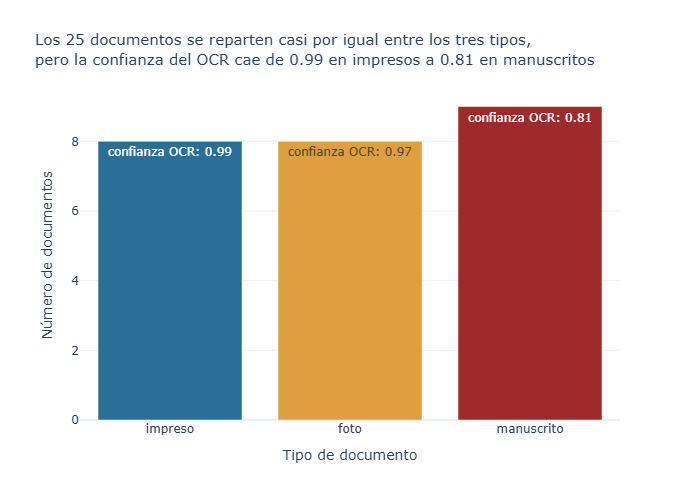

In [11]:
# Gráfico 1: documentos por tipo, con la confianza media del OCR en cada barra
docs_por_tipo = (documentos.groupby("tipo", sort=False)
                 .agg(documentos=("id", "size"), confianza=("confianza_media", "mean")).reset_index())
alta = docs_por_tipo.loc[docs_por_tipo.confianza.idxmax()]
baja = docs_por_tipo.loc[docs_por_tipo.confianza.idxmin()]

fig = px.bar(
    docs_por_tipo, x="tipo", y="documentos", color="tipo", color_discrete_map=COLORES_TIPO,
    text=docs_por_tipo.confianza.map(lambda c: f"confianza OCR: {c:.2f}"),
    labels={"tipo": "Tipo de documento", "documentos": "Número de documentos"},
    title=(f"Los {len(documentos)} documentos se reparten casi por igual entre los tres tipos,<br>"
           f"pero la confianza del OCR cae de {alta.confianza:.2f} en {alta.tipo}s a {baja.confianza:.2f} en {baja.tipo}s"),
)
fig.update_layout(showlegend=False)
mostrar(fig)

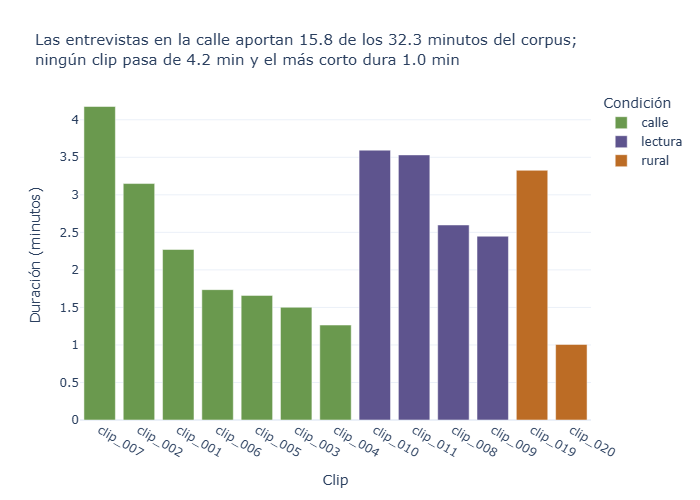

In [12]:
# Gráfico 2: duración de cada clip, coloreado por condición de grabación
clips = (transcripciones.assign(minutos=transcripciones.duracion_seg / 60)
         .sort_values("duracion_seg", ascending=False))
minutos_por_condicion = clips.groupby("condicion").minutos.sum().sort_values(ascending=False)
principal = minutos_por_condicion.index[0]

fig = px.bar(
    clips, x="id", y="minutos", color="condicion", color_discrete_map=COLORES_CONDICION,
    hover_data={"n_hablantes": True, "duracion_seg": True},
    labels={"id": "Clip", "minutos": "Duración (minutos)", "condicion": "Condición"},
    title=(f"{FRASE_CONDICION[principal].capitalize()} aportan {minutos_por_condicion.iloc[0]:.1f} "
           f"de los {clips.minutos.sum():.1f} minutos del corpus;<br>"
           f"ningún clip pasa de {clips.minutos.max():.1f} min y el más corto dura {clips.minutos.min():.1f} min"),
)
mostrar(fig)

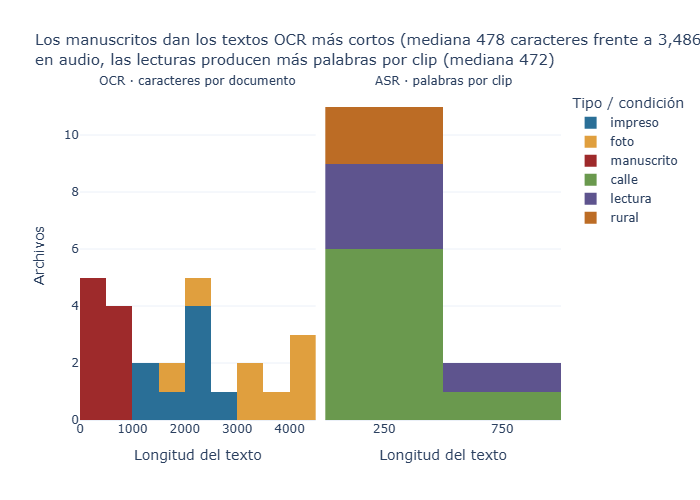

In [13]:
# Gráfico 3: histograma de longitud de los textos (caracteres OCR y palabras ASR)
longitudes = pd.concat([
    pd.DataFrame({"id": documentos.id, "medida": "OCR · caracteres por documento",
                  "grupo": documentos.tipo, "longitud": documentos.n_caracteres}),
    pd.DataFrame({"id": transcripciones.id, "medida": "ASR · palabras por clip",
                  "grupo": transcripciones.condicion, "longitud": transcripciones.n_palabras}),
])
mediana_tipo = documentos.groupby("tipo").n_caracteres.median()
mediana_condicion = transcripciones.groupby("condicion").n_palabras.median()

fig = px.histogram(
    longitudes, x="longitud", color="grupo", facet_col="medida", nbins=12,
    color_discrete_map=COLORES_TIPO | COLORES_CONDICION, hover_data=["id"],
    labels={"longitud": "Longitud del texto", "grupo": "Tipo / condición", "count": "Archivos"},
    title=(f"Los {mediana_tipo.idxmin()}s dan los textos OCR más cortos (mediana {mediana_tipo.min():,.0f} caracteres "
           f"frente a {mediana_tipo.max():,.0f} en {mediana_tipo.idxmax()}s);<br>"
           f"en audio, {FRASE_CONDICION[mediana_condicion.idxmax()]} producen más palabras por clip "
           f"(mediana {mediana_condicion.max():,.0f})"),
)
fig.update_xaxes(matches=None)   # cada panel con su propia escala: caracteres y palabras no se comparan
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_yaxes(title_text="Archivos", col=1)
mostrar(fig)

## 7. Validación

Los 3 documentos con el texto OCR más largo y más corto, y los 3 clips más largos y más cortos. Se comprueba que esos extremos coincidan con los bordes de los histogramas y que el contenido sea coherente con su tipo o condición.

In [14]:
def extremos(df, columna, columnas, texto):
    "Los 3 valores más altos y los 3 más bajos de una columna, con el inicio de su texto."
    tabla = pd.concat([df.nlargest(3, columna).assign(extremo="más largo"),
                       df.nsmallest(3, columna).assign(extremo="más corto")])
    tabla["inicio_del_texto"] = tabla[texto].str.replace(r"\s+", " ", regex=True).str[:90]
    return tabla[["extremo", *columnas, "inicio_del_texto"]]


display(extremos(documentos, "n_caracteres", ["id", "tipo", "n_caracteres", "n_lineas", "confianza_media"], "texto_ocr"))
display(extremos(transcripciones, "duracion_seg", ["id", "condicion", "duracion_seg", "n_palabras", "n_hablantes"], "texto_asr"))

# Coherencia con los histogramas: los extremos de las tablas son los bordes de cada panel
ocr_hist = longitudes[longitudes.medida.str.startswith("OCR")].longitud
asr_hist = longitudes[longitudes.medida.str.startswith("ASR")].longitud
assert documentos.n_caracteres.max() == ocr_hist.max() and documentos.n_caracteres.min() == ocr_hist.min()
print(f"OCR: de {ocr_hist.min()} a {ocr_hist.max()} caracteres, igual que el panel izquierdo del histograma.")
print(f"ASR: de {asr_hist.min()} a {asr_hist.max()} palabras por clip (panel derecho).")
correlacion = transcripciones[["duracion_seg", "n_palabras"]].corr(method="spearman").iloc[0, 1]
print(f"Duración y palabras por clip: correlación de Spearman = {correlacion:.2f} "
      "(los clips más largos deberían tener más palabras; un clip largo con pocas palabras sería sospechoso).")

,extremo,id,tipo,n_caracteres,n_lineas,confianza_media,inicio_del_texto
9,más largo,doc_010,foto,4317,107,0.973,HE t 1. INTRODUCCIÓN La popularidad del arbitraje en el Perú ha ido incre- mentando progre
8,más largo,doc_009,foto,4133,119,0.982,"icación etros mate. THÊMIS-Revista de Derecho 88. jullo-diclembre 2025. pp. 65-88, ISSN: 1"
13,más largo,doc_014,foto,4038,94,0.963,THÊMIS-Revista de Derecho 81. enero-julio 2022. pp. 43-61. ISSN: 1810-9934 S: Si la empres
20,más corto,doc_021,manuscrito,190,9,0.742,boradoes en lempir le he 'diehv solo gu es trabapt para en perirdi e0. Mcntras Tnga el tan
23,más corto,doc_024,manuscrito,389,18,0.792,complieadd pasa matert piresto que en desro is de Aor la Biblioteeer e(ped ta el dia 28. M
21,más corto,doc_022,manuscrito,418,21,0.838,5Y Clorinda Matto Tumer. DE Auguipa Juli 8 /84 S.D. Rueardo Palma Limia Mi guenido naestio


,extremo,id,condicion,duracion_seg,n_palabras,n_hablantes,inicio_del_texto
6,más largo,clip_007,calle,250.6,640,2,[HABLANTE_1] bueno ahora estamos en los san martín entre fiestas patrias de julio entonces
9,más largo,clip_010,lectura,215.7,499,1,"[HABLANTE_1] Huaca Puente Inca, en Wikipedia la enciclopedia libre, https.es.wikipedia.org"
10,más largo,clip_011,lectura,211.9,532,1,"[HABLANTE_1] El sitio arqueológico del Naranjal, denominado también Huaca del Naranjal, se"
12,más corto,clip_020,rural,60.4,63,2,[HABLANTE_1] ¿Cuál es la planta? [HABLANTE_2] ¿Cuál es la planta? [HABLANTE_1] ¿Cuál es la
3,más corto,clip_004,calle,75.9,184,3,"[HABLANTE_1] Sí, ok, digamos, ¿qué es el Perú para usted? [HABLANTE_2] El Perú para mí es"
2,más corto,clip_003,calle,90.1,60,2,[HABLANTE_1] ¿Qué es el Perú para mí? Siento parte de la cultura pegana. [HABLANTE_2] ¿Cuá


OCR: de 190 a 4317 caracteres, igual que el panel izquierdo del histograma.
ASR: de 60 a 640 palabras por clip (panel derecho).
Duración y palabras por clip: correlación de Spearman = 0.93 (los clips más largos deberían tener más palabras; un clip largo con pocas palabras sería sospechoso).


## 8. Exportación

Se guardan tres archivos en `datos/`:

- `documentos.csv`: las columnas obligatorias (`id`, `archivo`, `tipo`, `fuente`, `texto_ocr`, `modelo_ocr`, `texto_referencia`) más métricas del OCR y `publicar_imagen`, que indica si la licencia permite mostrar la imagen en el dashboard.
- `transcripciones.csv`: las columnas obligatorias (`id`, `archivo_audio`, `duracion_seg`, `idioma`, `texto_asr`, `modelo_asr`, `n_hablantes`, `texto_referencia`) más la condición de grabación, la atribución y el RTF.
- `fuentes.csv`: una fila por archivo descargado, **incluidos los descartados**, con `id`, `modalidad`, `fuente_url`, `licencia`, `acceso` (cómo recuperarlo) y `estado`.

`texto_referencia` lleva la transcripción manual de los 10 documentos y 10 clips de la muestra de evaluación (Parte 2), escrita a mano en `datos/raw/referencias/<id>.txt`; las de audio pasan por la misma seudonimización que el texto ASR. En los demás archivos queda vacío. Las URL de Commons conservan el título que le dio su autor (en algunos casos con el nombre de la persona entrevistada) porque la licencia CC BY-SA exige enlazar la fuente; los textos publicados no repiten esos nombres.

In [15]:
BNP_DIGITAL = " ; ".join(f"https://bibliotecadigital.bnp.gob.pe/items/{uuid}" for uuid in [
    "d2c6e978-52d4-4bb0-9f95-5104a308837c", "00383e3a-518b-4397-9dcb-fe2710f3ab7b",
    "661a505e-5dc5-411a-a174-2ef8499bd0f7", "5bd20bc1-c0b3-49c6-9beb-c2f5bc467bb6"])


def fuente_documento(tipo, numero):
    "(origen, url, licencia, acceso, publicar_imagen) de cada documento según su tipo y número."
    if tipo == "impreso":
        return ("Revista Fénix n.º 19 (1969), Biblioteca Nacional del Perú",
                "https://revistafenix.bnp.gob.pe/index.php/fenix/article/view/515", "CC BY-NC-ND 4.0",
                "Descargar el PDF del artículo (pp. 67-77) desde la página de la revista", True)
    if tipo == "manuscrito":
        return ("Biblioteca Digital de la Biblioteca Nacional del Perú", BNP_DIGITAL, "Dominio público",
                "Descargar la imagen desde la ficha del ítem en BNP Digital", True)
    if numero in (1, 2):
        return ("THĒMIS-Revista de Derecho n.º 88 (2025), fotografía propia",
                "https://revistas.pucp.edu.pe/index.php/themis/es/article/view/33548", "CC BY 4.0",
                "Fotografía propia del ejemplar impreso; el número está publicado en revistas.pucp.edu.pe", True)
    if numero in (3, 4):
        return ("Estudio de anulación de laudos 2022, Centro de Arbitraje de la Cámara de Comercio de Lima, fotografía propia",
                "https://www.arbitrajeccl.com.pe/wp-content/uploads/2024/04/Estudio-de-anulacion-de-laudos-2022.pdf",
                "Sin licencia declarada (derechos reservados); uso académico",
                f"Fotografía propia del ejemplar impreso; texto en el PDF, p. {24 if numero == 3 else 45}", False)
    articulo = 26498 if numero == 5 else 26490
    return ("THĒMIS-Revista de Derecho n.º 81 (2022), fotografía propia",
            f"https://revistas.pucp.edu.pe/index.php/themis/es/article/view/{articulo}", "CC BY 4.0",
            "Fotografía propia del ejemplar impreso; el artículo está publicado en revistas.pucp.edu.pe", True)


REFERENCIAS = DATOS / "raw" / "referencias"


def referencias_manuales(archivo_csv, ids):
    "Transcripción manual (Parte 2): datos/raw/referencias/<id>.txt o, si no existe, la que ya tenía el CSV."
    anteriores = {}
    if archivo_csv.exists():
        previo = pd.read_csv(archivo_csv, keep_default_na=False)
        anteriores = dict(zip(previo.id, previo.texto_referencia))
    return [(REFERENCIAS / f"{i}.txt").read_text(encoding="utf-8").strip() if (REFERENCIAS / f"{i}.txt").exists()
            else anteriores.get(i, "") for i in ids]


# Fuente de TODOS los documentos (también de los descartados, para fuentes.csv)
info_docs = pd.DataFrame(
    [(d.id, *fuente_documento(d.tipo, numero_de(Path(d.archivo)))) for d in ocr_docs.itertuples()],
    columns=["id", "origen", "fuente_url", "licencia", "acceso", "publicar_imagen"])
documentos = documentos.merge(info_docs, on="id")
documentos["fuente"] = documentos.origen + " (" + documentos.licencia + ")"
documentos["texto_referencia"] = [reemplazar_patrones(t)[0] for t in
                                  referencias_manuales(DATOS / "documentos.csv", documentos.id)]

transcripciones["idioma"] = "es"
transcripciones["fuente"] = "Wikimedia Commons, " + transcripciones.autor + " (" + transcripciones.licencia + ")"
# las referencias de audio pasan por la misma seudonimización que el texto ASR
transcripciones["texto_referencia"] = [seudonimizar_audio(t)[0] for t in
                                       referencias_manuales(DATOS / "transcripciones.csv", transcripciones.id)]

COLUMNAS_DOCS = ["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia",
                 "n_lineas", "n_caracteres", "confianza_media", "publicar_imagen"]
COLUMNAS_ASR = ["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes",
                "texto_referencia", "condicion", "fuente", "n_palabras", "rtf"]
documentos[COLUMNAS_DOCS].to_csv(DATOS / "documentos.csv", index=False, encoding="utf-8")
transcripciones[COLUMNAS_ASR].to_csv(DATOS / "transcripciones.csv", index=False, encoding="utf-8")

# fuentes.csv: todos los archivos descargados, incluidos los descartados
fuentes = pd.concat([
    info_docs.assign(modalidad="documento")[["id", "modalidad", "fuente_url", "licencia", "acceso"]],
    audios.assign(
        modalidad="audio",
        fuente_url=audios.url_pagina,
        licencia=audios.licencia + ", autor en Commons: " + audios.autor,
        acceso="Descargar el original desde la página de Commons y convertirlo: "
               "ffmpeg -i <original> -ac 1 -ar 16000 " + audios.id + ".wav",
    )[["id", "modalidad", "fuente_url", "licencia", "acceso"]],
], ignore_index=True)
fuentes["estado"] = ["descartado" if i in set(descartes.id) else "incluido" for i in fuentes.id]
fuentes.to_csv(DATOS / "fuentes.csv", index=False, encoding="utf-8")

for nombre, df in [("documentos.csv", documentos[COLUMNAS_DOCS]),
                   ("transcripciones.csv", transcripciones[COLUMNAS_ASR]),
                   ("fuentes.csv", fuentes)]:
    print(f"datos/{nombre}: {df.shape}")

datos/documentos.csv: (25, 11)
datos/transcripciones.csv: (13, 12)
datos/fuentes.csv: (45, 6)


In [16]:
display(pd.read_csv(DATOS / "documentos.csv").head(5))
display(pd.read_csv(DATOS / "transcripciones.csv").head(5))
display(pd.read_csv(DATOS / "fuentes.csv").head(5))

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia,n_lineas,n_caracteres,confianza_media,publicar_imagen
0,doc_001,datos/raw/documentos/Impreso-nitido-1.png,impreso,"Revista Fénix n.º 19 (1969), Biblioteca Nacional del Perú (CC BY-NC-ND 4.0)",UN MANUSCRITO AUTOGRAFO Y DESCONOCIDO\nDE MARIANO MELGAR\nEstuardo Núñez\nLa Biblioteca de Lilly de la Universidad d...,"PaddleOCR 3.7 · PP-OCRv6_medium (lang=es, CPU, sin preprocesamiento)",UN MANUSCRITO AUTOGRAFO Y DESCONOCIDO DE MARIANO MELGAR \nEstuardo Núñez \nLa Biblioteca de Lilly de la Universidad ...,33,2247,0.990,True
1,doc_002,datos/raw/documentos/Impreso-nitido-2.png,impreso,"Revista Fénix n.º 19 (1969), Biblioteca Nacional del Perú (CC BY-NC-ND 4.0)","68\nFENIX\ny ""El ruiseñor y el calesero"", y ""El Sol"", no aparecieron en la edición de 1878,\nsino en otras publicaci...","PaddleOCR 3.7 · PP-OCRv6_medium (lang=es, CPU, sin preprocesamiento)","68 FENIX \ny “El ruiseñor y el calesero”, y “El Sol”, no aparecieron en la edición de 1878, sino en otras publicacio...",60,2325,0.996,True
2,doc_003,datos/raw/documentos/Impreso-nitido-3.png,impreso,"Revista Fénix n.º 19 (1969), Biblioteca Nacional del Perú (CC BY-NC-ND 4.0)",UN MANUSCRITO DESCONOCIDO DE MELGAR\n69\nel sentimiento patriótico de las masas y canalizar el entusiasmo por la cau...,"PaddleOCR 3.7 · PP-OCRv6_medium (lang=es, CPU, sin preprocesamiento)",UN MANUSCRITO DESCONOCIDO DE MELGAR 69 \nel sentimiento patriótico de las masas y canalizar el entusiasmo por la cau...,40,2668,0.994,True
3,doc_004,datos/raw/documentos/Impreso-nitido-4.png,impreso,"Revista Fénix n.º 19 (1969), Biblioteca Nacional del Perú (CC BY-NC-ND 4.0)","70\nFENIX\nLA BALLENA Y EL LOBO\nMirando con desprecio á cuantos peces\nPueblan el ancho mar, una Ballena\nDecía á b...","PaddleOCR 3.7 · PP-OCRv6_medium (lang=es, CPU, sin preprocesamiento)",NaN,43,2000,0.994,True
4,doc_005,datos/raw/documentos/Impreso-nitido-5.png,impreso,"Revista Fénix n.º 19 (1969), Biblioteca Nacional del Perú (CC BY-NC-ND 4.0)","UN MANUSCRITO DESCONOCIDO DE MELGAR\n71\nDice Ia primera, un yaraví en tercetos de pie quebrado (como los yaravíes c...","PaddleOCR 3.7 · PP-OCRv6_medium (lang=es, CPU, sin preprocesamiento)",NaN,46,1115,0.995,True


,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia,condicion,fuente,n_palabras,rtf
0,clip_001,datos/raw/audio/clip_001.wav,136.3,es,"[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme su opinión acerca del partido d...","faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD Silero) + diarización WeSpeaker",2,NaN,calle,"Wikimedia Commons, JorgeFlores-pe (CC BY-SA 4.0)",265,1.19
1,clip_002,datos/raw/audio/clip_002.wav,189.0,es,"[HABLANTE_1] Buenos días profesor y compañeros, hoy estoy cerca de aquí por mi casa y voy a hacer una entrevista ace...","faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD Silero) + diarización WeSpeaker",3,Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a hacer entrevistas cerca del fútbol co...,calle,"Wikimedia Commons, JorgeFlores-pe (CC BY-SA 4.0)",364,0.88
2,clip_003,datos/raw/audio/clip_003.wav,90.1,es,[HABLANTE_1] ¿Qué es el Perú para mí? Siento parte de la cultura pegana.\n[HABLANTE_2] ¿Cuáles son sus característic...,"faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD Silero) + diarización WeSpeaker",2,Quisiera saber si le gustaría participar en este video. Si.¿Qué es el Perú para usted?¿Qué es el Perú para mí? Bueno...,calle,"Wikimedia Commons, Rosario MQ (CC BY-SA 4.0)",60,0.23
3,clip_004,datos/raw/audio/clip_004.wav,75.9,es,"[HABLANTE_1] Sí, ok, digamos, ¿qué es el Perú para usted?\n[HABLANTE_2] El Perú para mí es un país en desarrollo, pe...","faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD Silero) + diarización WeSpeaker",3,"Para mi tarea universitaria? Si. Gracias ¿Qué es el Perú para usted? El Perú para mí es un país en desarrollo, pero ...",calle,"Wikimedia Commons, Rosario MQ (CC BY-SA 4.0)",184,0.80
4,clip_005,datos/raw/audio/clip_005.wav,99.6,es,"[HABLANTE_1] ¿Eso representa la capa de interés? ...a la vida de Venezuela, la guerra... ...que nada, cuando piense ...","faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD Silero) + diarización WeSpeaker",2,NaN,calle,"Wikimedia Commons, Christopher Bellido (CC BY-SA 4.0)",76,0.94


,id,modalidad,fuente_url,licencia,acceso,estado
0,doc_001,documento,https://revistafenix.bnp.gob.pe/index.php/fenix/article/view/515,CC BY-NC-ND 4.0,Descargar el PDF del artículo (pp. 67-77) desde la página de la revista,incluido
1,doc_002,documento,https://revistafenix.bnp.gob.pe/index.php/fenix/article/view/515,CC BY-NC-ND 4.0,Descargar el PDF del artículo (pp. 67-77) desde la página de la revista,incluido
2,doc_003,documento,https://revistafenix.bnp.gob.pe/index.php/fenix/article/view/515,CC BY-NC-ND 4.0,Descargar el PDF del artículo (pp. 67-77) desde la página de la revista,incluido
3,doc_004,documento,https://revistafenix.bnp.gob.pe/index.php/fenix/article/view/515,CC BY-NC-ND 4.0,Descargar el PDF del artículo (pp. 67-77) desde la página de la revista,incluido
4,doc_005,documento,https://revistafenix.bnp.gob.pe/index.php/fenix/article/view/515,CC BY-NC-ND 4.0,Descargar el PDF del artículo (pp. 67-77) desde la página de la revista,incluido


### Muestra publicable para el dashboard (`datos/ejemplos/`)

Los originales no se versionan, así que el dashboard usa una muestra pequeña y liviana:

- **Imágenes:** 2 documentos por tipo, solo entre los que su licencia permite publicar (`publicar_imagen`), en JPEG de 900 px de ancho.
- **Audio:** 1 clip por condición de grabación, solo entre los que no contenían nombres de personas (0 entidades seudonimizadas), en MP3 mono de 64 kbps. Se prefiere el clip con más hablantes para mostrar la diarización. La licencia CC BY-SA 4.0 permite redistribuirlos citando al autor.

In [17]:
import shutil
import subprocess

EJEMPLOS = DATOS / "ejemplos"
EJEMPLOS.mkdir(exist_ok=True)

imagenes = documentos[documentos.publicar_imagen.astype(bool)].groupby("tipo", sort=False).head(2)
for doc in imagenes.itertuples():
    imagen = Image.open(doc.archivo).convert("RGB")
    imagen.thumbnail((900, 1400))
    imagen.save(EJEMPLOS / f"{doc.id}.jpg", quality=80)

sin_nombres = transcripciones[transcripciones.entidades_reemplazadas.astype(int) == 0]
audios_muestra = (sin_nombres.sort_values(["n_hablantes", "duracion_seg"], ascending=[False, True])
                  .groupby("condicion").head(1))
ffmpeg = shutil.which("ffmpeg")
for clip in audios_muestra.itertuples():
    subprocess.run([ffmpeg, "-y", "-loglevel", "error", "-i", clip.archivo_audio,
                    "-ac", "1", "-b:a", "64k", str(EJEMPLOS / f"{clip.id}.mp3")], check=True)

for archivo in sorted(EJEMPLOS.iterdir()):
    print(f"{archivo.as_posix():<32} {archivo.stat().st_size / 1024:>6.0f} KB")

datos/ejemplos/clip_004.mp3         594 KB
datos/ejemplos/clip_008.mp3        1219 KB
datos/ejemplos/clip_020.mp3         473 KB
datos/ejemplos/doc_001.jpg          107 KB
datos/ejemplos/doc_002.jpg          111 KB
datos/ejemplos/doc_009.jpg          251 KB
datos/ejemplos/doc_010.jpg          285 KB
datos/ejemplos/doc_017.jpg           98 KB
datos/ejemplos/doc_018.jpg          118 KB
